# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StickRift/Rift/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

## Research Question

Can historical content freshness and search-performance signals be used to identify and prioritise web pages that may need content review?

## Problem

Websites can contain thousands of published pages. Reviewing every page individually takes time, so content teams need a practical way to decide which pages deserve attention first.

Some pages may have gone a long time without an update, while others may show changes in search visibility or performance. Examining these signals together could help identify pages that deserve closer investigation.

## Decision This Research Supports

This research aims to support content teams in prioritising pages for human review using historical content freshness and Google Search Console performance signals.

The intended outcome is a decision-support approach that helps reviewers decide which pages to investigate first. It does not automatically determine which pages should be updated or guarantee that an update will improve search performance.

## Research Objective

To examine the relationship between historical content freshness, search-performance signals, and subsequent changes in search impressions, and evaluate whether these signals can help prioritise content for review.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

## Dataset and Data Sources

This research uses the FlyRank internship warehouse, release `v20260703`, hosted on Hugging Face.

The warehouse contains anonymized search-performance and content information. The research uses two main tables:

- `fact_content_daily_performance`: Daily Google Search Console performance records for individual content items and clients.
- `dim_content`: Content information, including creation dates, update dates, word counts, search volume and backlinks.

The content dimension contains 519,606 records. The daily performance table contains approximately 78.8 million records across the available reporting period.

## Date Coverage

The warehouse covers January 2025 through June 2026.

The initial investigation examined monthly data availability from January 2025 through June 2026. The modelling dataset was initially constructed using historical feature periods from October 2025 through May 2026, paired with the following month as the outcome period.

June 2026 is the warehouse's final sealed month. Results involving June as an outcome are treated as preliminary and are not presented as an untouched final test.

## Data Preparation and Exclusions

The research uses Google Search Console records only when `gsc_data_available` is TRUE. Records without usable search data are excluded rather than interpreted as zero impressions or clicks.

Monthly content records must have at least 15 usable search-performance days in both the feature month and the following outcome month.

Content records with missing update dates or update dates later than the feature period are excluded from the freshness analysis.

Client and content identifiers are used for joining records and separating clients during validation. They are not used as predictive features.

The modelling process focuses on historical freshness and search-performance information. Future outcome information is kept separate from the predictive features.

## Privacy

The warehouse contains anonymized research data. No client names, website addresses, private search queries, credentials or raw identifying information are included in the public research output.

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

## Methodology

### Research Approach

This research uses a supervised machine-learning approach to examine whether historical content freshness and search-performance signals can help identify pages that experience a subsequent decline in search impressions.

Each modelling record represents one content item for a particular feature month.

### Features

The model uses five historical features:

- `days_since_update`: Number of days since the content was last updated.
- `avg_daily_impressions`: Average daily Google Search Console impressions during the feature month.
- `avg_daily_clicks`: Average daily clicks during the feature month.
- `ctr`: Click-through rate calculated from clicks and impressions.
- `avg_position`: Average recorded search position during the feature month.

These features represent information available during the feature period.

### Target Variable

The target is `impressions_declined`.

It is assigned a value of 1 when the following month's average daily impressions are lower than the feature month's average daily impressions. Otherwise, it is assigned 0.

This measures a directional change in impressions. It does not establish why the change occurred.

### Baseline

A Dummy Classifier using the most frequent training outcome provides a simple benchmark. The Random Forest model must be compared against this baseline using the same test records.

### Machine-Learning Model

A Random Forest classifier is used to examine relationships between the five historical features and the subsequent impressions outcome.

Missing feature values are handled using median imputation within the modelling pipeline. Class weighting is used to account for differences in the number of records in each outcome class.

### Validation Design

The final evaluation uses a chronological feature-period split and client-level separation.

- Training feature periods: February and March 2026.
- Training outcomes: March and April 2026.
- Testing feature period: April 2026.
- Testing outcome: May 2026.

Clients assigned to the training group are excluded from the testing group. This prevents the same clients from appearing in both groups.

June 2026 is excluded from model development and evaluation because it is the sealed final month.

### Leakage Prevention

Only historical feature-period information is used as model input.

The following information is excluded from the feature set:

- Next-month impressions.
- The target variable.
- Client and content identifiers.
- Information that would only become available after the feature period.

The purpose of these checks is to reduce the risk of future information influencing model predictions.

In [24]:
from sklearn.model_selection import train_test_split

# Use only February, March and April feature periods.
# April is the final testing feature period.
capstone_data = model_data[
    model_data["feature_month"].isin([
        "2026-02",
        "2026-03",
        "2026-04"
    ])
].copy()

# Separate clients to prevent client overlap.
clients = capstone_data["client_hash_id"].unique()

train_clients, test_clients = train_test_split(
    clients,
    test_size=0.20,
    random_state=42
)

# Training: February and March features.
train_data = capstone_data[
    (capstone_data["feature_month"].isin(["2026-02", "2026-03"])) &
    (capstone_data["client_hash_id"].isin(train_clients))
].copy()

# Testing: April features, with May as the outcome.
test_data = capstone_data[
    (capstone_data["feature_month"] == "2026-04") &
    (capstone_data["client_hash_id"].isin(test_clients))
].copy()

features = [
    "days_since_update",
    "avg_daily_impressions",
    "avg_daily_clicks",
    "ctr",
    "avg_position"
]

target = "impressions_declined"

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print("TRAINING ROWS:", len(train_data))
print("TESTING ROWS:", len(test_data))

print("TRAINING CLIENTS:", train_data["client_hash_id"].nunique())
print("TESTING CLIENTS:", test_data["client_hash_id"].nunique())

print("CLIENT OVERLAP:",
      len(set(train_data["client_hash_id"]) &
          set(test_data["client_hash_id"])))

print("TRAINING MONTHS:",
      sorted(train_data["feature_month"].unique()))

print("TESTING MONTH:",
      sorted(test_data["feature_month"].unique()))

print("TRAINING DECLINE RATE:",
      round(y_train.mean() * 100, 2), "%")

print("TESTING DECLINE RATE:",
      round(y_test.mean() * 100, 2), "%")

TRAINING ROWS: 23876
TESTING ROWS: 6796
TRAINING CLIENTS: 23
TESTING CLIENTS: 5
CLIENT OVERLAP: 0
TRAINING MONTHS: ['2026-02', '2026-03']
TESTING MONTH: ['2026-04']
TRAINING DECLINE RATE: 55.24 %
TESTING DECLINE RATE: 74.87 %


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [25]:
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# 1. Baseline model
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]

# 2. Random Forest model
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

model_predictions = model.predict(X_test)
model_probabilities = model.predict_proba(X_test)[:, 1]

# 3. Compare both models
results = []

for name, predictions, probabilities in [
    ("Baseline", baseline_predictions, baseline_probabilities),
    ("Random Forest", model_predictions, model_probabilities)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).set_index("Model")

print("MODEL COMPARISON")
display(results_df.round(4))

print("\nBASELINE CONFUSION MATRIX")
print(confusion_matrix(y_test, baseline_predictions))

print("\nRANDOM FOREST CONFUSION MATRIX")
print(confusion_matrix(y_test, model_predictions))

MODEL COMPARISON


,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Model,,,,,,,
Baseline,0.7487,0.5000,0.7487,1.0000,0.8563,0.5000,0.7487
Random Forest,0.6953,0.6096,0.8054,0.7818,0.7935,0.6772,0.8536



BASELINE CONFUSION MATRIX
[[   0 1708]
 [   0 5088]]

RANDOM FOREST CONFUSION MATRIX
[[ 747  961]
 [1110 3978]]


### Model Performance

The Random Forest model was evaluated against a majority-class baseline using the same testing dataset.

The baseline achieved an accuracy of 74.87%, while the Random Forest achieved 69.53%. However, the Random Forest performed better in balanced accuracy (60.96% versus 50.00%), precision (80.54% versus 74.87%), ROC-AUC (0.6772 versus 0.5000), and average precision (0.8536 versus 0.7487).

The baseline predicted every testing observation as a decline. Although this produced a high recall of 100%, it could not distinguish between declining and non-declining content.

The Random Forest identified both classes more effectively, although it missed some actual declines and generated some false alarms. Its results suggest that historical freshness and search-performance signals contain useful information for prioritising content for human review.

Overall, the model provides a more informative ranking signal than the simple baseline, but its performance is not strong enough to justify automatic content decisions. The results should be interpreted cautiously because the testing set contains only five clients and has a higher decline rate than the training set.

## 5. Limitations

*What this work cannot claim.*

### Limitations

This analysis has several limitations that affect how its results should be interpreted.

1. **Limited testing clients:** The testing dataset contains only five clients. Although the model was tested on clients excluded from training, this small number limits how confidently the results can be generalised to other clients.

2. **Different decline rates:** The training dataset had a decline rate of 55.24%, compared with 74.87% in testing. This difference suggests that the testing data has a different distribution, which may affect model performance.

3. **Incomplete search data:** Not every content item has usable Google Search Console data. Records without available search data were excluded rather than treated as zero.

4. **Limited features:** The model uses five historical signals: days since update, average daily impressions, average daily clicks, CTR, and average position. Other factors that may influence search performance were not included.

5. **No causal evidence:** The analysis identifies relationships between historical signals and subsequent changes in impressions. It does not prove that updating content causes search performance to improve or decline.

6. **Model performance:** Although the Random Forest performs better than the baseline on several ranking and classification measures, its ROC-AUC of 0.6772 indicates that its ability to distinguish between the two classes remains limited.

### Interpretation

These limitations mean that the model should be treated as a decision-support tool for prioritising human content review, not as an automatic decision-maker or a guarantee of future search performance.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

### Recommendation Approach

The Random Forest model's predicted probabilities are used to rank eligible content items from highest to lowest estimated likelihood of an impressions decline.

The highest-ranked items should receive earlier human review. The ranking is intended to support prioritisation, not automatic content updates.

Three practical review priorities are recommended:

1. **High priority:** Review items with higher predicted decline probabilities first. Examine their freshness and recent search-performance signals.
2. **Secondary priority:** Review items with moderate predicted probabilities, especially where content has not been updated recently.
3. **Lower priority:** Continue monitoring items with lower predicted probabilities rather than assuming they are permanently safe.

### Reason Codes

To make the recommendations easier to interpret, each ranked item receives a reason code based on two signals:

- **Staleness:** Whether the content has not been updated for more than 90 days.
- **Visibility:** Whether its average daily impressions are at or above the testing dataset's median.

These reason codes provide context for human review. They are not proof that either signal causes an impressions decline.

The ranked list is a decision-support output. Content teams should inspect the page and its context before deciding whether an update is appropriate.

In [26]:
# Rank testing items using Random Forest probabilities

ranked = test_data.copy()

ranked["predicted_decline_probability"] = model.predict_proba(X_test)[:, 1]

# Define the two review signals
visibility_threshold = ranked["avg_daily_impressions"].median()

ranked["stale"] = ranked["days_since_update"] > 90
ranked["visible"] = ranked["avg_daily_impressions"] >= visibility_threshold

# Assign reason codes
ranked["reason_code"] = "NO_PRIORITY_SIGNAL"

ranked.loc[
    ranked["stale"] & ranked["visible"],
    "reason_code"
] = "STALE_AND_VISIBLE"

ranked.loc[
    ranked["stale"] & ~ranked["visible"],
    "reason_code"
] = "STALE_ONLY"

ranked.loc[
    ~ranked["stale"] & ranked["visible"],
    "reason_code"
] = "VISIBLE_ONLY"

# Rank highest predicted probabilities first
ranked = ranked.sort_values(
    "predicted_decline_probability",
    ascending=False
).reset_index(drop=True)

ranked["rank"] = ranked.index + 1

# Select the top 20 without exposing identifiers
top_20 = ranked.head(20)[[
    "rank",
    "predicted_decline_probability",
    "days_since_update",
    "avg_daily_impressions",
    "reason_code"
]].copy()

top_20["review_item"] = [
    f"Review item {i}" for i in range(1, len(top_20) + 1)
]

top_20 = top_20[[
    "rank",
    "review_item",
    "predicted_decline_probability",
    "days_since_update",
    "avg_daily_impressions",
    "reason_code"
]]

print("TOP 20 CONTENT ITEMS FOR HUMAN REVIEW")
display(top_20.round(4))

print("\nREASON CODE COUNTS IN TOP 20")
display(top_20["reason_code"].value_counts().to_frame("count"))

print("\nMEDIAN IMPRESSIONS THRESHOLD:",
      round(visibility_threshold, 2))

TOP 20 CONTENT ITEMS FOR HUMAN REVIEW


,rank,review_item,predicted_decline_probability,days_since_update,avg_daily_impressions,reason_code
0,1,Review item 1,0.8223,16,44.2500,VISIBLE_ONLY
1,2,Review item 2,0.8039,28,68.6333,VISIBLE_ONLY
2,3,Review item 3,0.7995,15,10.4828,NO_PRIORITY_SIGNAL
3,4,Review item 4,0.7933,28,9.2759,NO_PRIORITY_SIGNAL
4,5,Review item 5,0.7919,28,20.1333,NO_PRIORITY_SIGNAL
5,6,Review item 6,0.7839,28,20.3000,NO_PRIORITY_SIGNAL
6,7,Review item 7,0.7730,15,8.5789,NO_PRIORITY_SIGNAL
7,8,Review item 8,0.7699,28,7.7000,NO_PRIORITY_SIGNAL
8,9,Review item 9,0.7657,28,23.0333,NO_PRIORITY_SIGNAL
9,10,Review item 10,0.7420,28,79.6333,VISIBLE_ONLY



REASON CODE COUNTS IN TOP 20


,count
reason_code,
VISIBLE_ONLY,11
NO_PRIORITY_SIGNAL,9



MEDIAN IMPRESSIONS THRESHOLD: 23.25


### Top-20 Ranking Findings

The Random Forest model generated a ranked list of the 20 highest-priority content items for human review.

Predicted decline probabilities ranged from 68.58% to 82.23%.

The reason-code analysis showed:

- 11 items were classified as VISIBLE_ONLY.
- 9 items were classified as NO_PRIORITY_SIGNAL.
- No items were classified as STALE_ONLY or STALE_AND_VISIBLE.

The visibility threshold was 23.25 average daily impressions. None of the top 20 items had exceeded 90 days since its last recorded update.

### Recommended Actions

1. **Review high-ranked items first:** Begin with items that have the highest predicted decline probabilities.
2. **Investigate search visibility:** For the 11 VISIBLE_ONLY items, inspect their search performance, target queries, and opportunities to improve relevance.
3. **Investigate other performance signals:** For the 9 NO_PRIORITY_SIGNAL items, examine their broader search-performance history rather than assuming content age is the problem.
4. **Avoid automatic updates:** Require human assessment before changing any content.
5. **Monitor outcomes:** Compare subsequent impressions with the predictions to understand whether the ranking is useful in practice.

### Overall Recommendation

The ranking suggests that historical search-performance signals can help identify content items for further investigation. Content freshness alone did not explain the composition of the top-20 list. The ranking should therefore be used as a starting point for human review, not as proof that an item requires an update.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

### Research Artifacts

The following artifacts support the findings presented in the research paper:

1. **Model comparison table:** Shows how the Random Forest performed against the majority-class baseline across classification and ranking metrics.
2. **Top-20 review list:** Shows the highest-ranked content items and their predicted decline probabilities, using anonymised review labels.
3. **Model comparison chart:** Provides a visual comparison of the two models' performance.

These artifacts make the analysis easier to inspect and help readers understand how the findings support the recommendations.

The ranked review list excludes client and content identifiers to protect the privacy of the dataset.

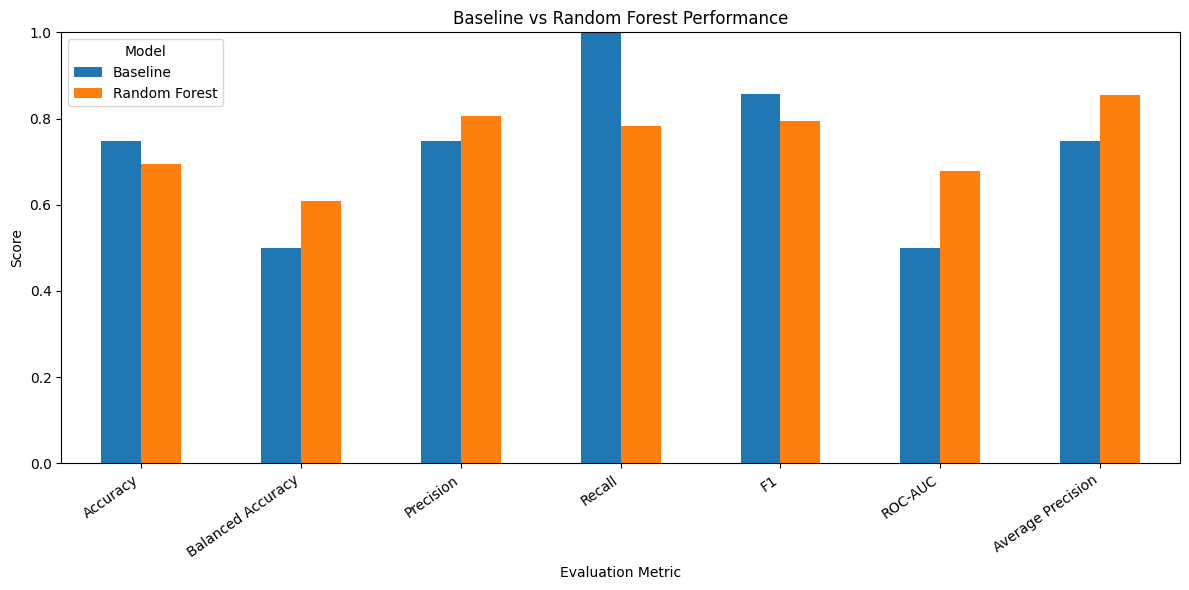

SAVED ARTIFACTS:
1. work/outputs/capstone_model_comparison.csv
2. work/outputs/capstone_top20_review.csv
3. work/outputs/capstone_model_comparison.png


In [27]:
import os
import matplotlib.pyplot as plt

# Create output folder
os.makedirs("work/outputs", exist_ok=True)

# Save model comparison table
results_df.to_csv(
    "work/outputs/capstone_model_comparison.csv"
)

# Save anonymised top-20 ranking
top_20.to_csv(
    "work/outputs/capstone_top20_review.csv",
    index=False
)

# Create model comparison chart
metrics_to_plot = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "Average Precision"
]

results_df[metrics_to_plot].T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Baseline vs Random Forest Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    "work/outputs/capstone_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SAVED ARTIFACTS:")
print("1. work/outputs/capstone_model_comparison.csv")
print("2. work/outputs/capstone_top20_review.csv")
print("3. work/outputs/capstone_model_comparison.png")

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.


In [44]:
import os

required_files = [
    "work/outputs/capstone_model_comparison.csv",
    "work/outputs/capstone_top20_review.csv",
    "work/outputs/capstone_model_comparison.png"
]

for file in required_files:
    print(
        "FOUND:" if os.path.exists(file) else "MISSING:",
        file
    )

FOUND: work/outputs/capstone_model_comparison.csv
FOUND: work/outputs/capstone_top20_review.csv
FOUND: work/outputs/capstone_model_comparison.png


In [46]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/capstone_outputs",
    "zip",
    "work/outputs"
)

files.download("/content/capstone_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
from google.colab import userdata

HF_TOKEN = userdata.get("FLYRANK_HF_TOKEN")

if HF_TOKEN:
    print("Hugging Face token loaded successfully.")
else:
    print("Token not found. Check your Colab Secrets settings.")

Hugging Face token loaded successfully.


In [29]:
!pip install -q duckdb

In [30]:
import duckdb
from google.colab import userdata

HF_TOKEN = userdata.get("FLYRANK_HF_TOKEN")

con = duckdb.connect()

con.execute("""
    CREATE SECRET hf_token (
        TYPE huggingface,
        TOKEN ?
    )
""", [HF_TOKEN])

print("DuckDB connected and Hugging Face authentication configured.")

DuckDB connected and Hugging Face authentication configured.


In [31]:
import requests

url = "https://huggingface.co/api/datasets/FlyRank/internship-warehouse/tree/main"

response = requests.get(
    url,
    headers={"Authorization": f"Bearer {HF_TOKEN}"},
    params={"recursive": "true", "expand": "false"}
)

response.raise_for_status()

files = response.json()

parquet_files = [
    item["path"] for item in files
    if item["path"].endswith(".parquet")
]

print("Number of Parquet files:", len(parquet_files))

for file in parquet_files[:20]:
    print(file)

Number of Parquet files: 22
dim_clients.parquet
dim_content.parquet
fact_content_daily_performance/month=2025-01/data_0.parquet
fact_content_daily_performance/month=2025-02/data_0.parquet
fact_content_daily_performance/month=2025-03/data_0.parquet
fact_content_daily_performance/month=2025-04/data_0.parquet
fact_content_daily_performance/month=2025-05/data_0.parquet
fact_content_daily_performance/month=2025-06/data_0.parquet
fact_content_daily_performance/month=2025-07/data_0.parquet
fact_content_daily_performance/month=2025-08/data_0.parquet
fact_content_daily_performance/month=2025-09/data_0.parquet
fact_content_daily_performance/month=2025-10/data_0.parquet
fact_content_daily_performance/month=2025-11/data_0.parquet
fact_content_daily_performance/month=2025-12/data_0.parquet
fact_content_daily_performance/month=2026-01/data_0.parquet
fact_content_daily_performance/month=2026-02/data_0.parquet
fact_content_daily_performance/month=2026-03/data_0.parquet
fact_content_daily_performance/m

In [32]:
for file in parquet_files:
    print(file)

dim_clients.parquet
dim_content.parquet
fact_content_daily_performance/month=2025-01/data_0.parquet
fact_content_daily_performance/month=2025-02/data_0.parquet
fact_content_daily_performance/month=2025-03/data_0.parquet
fact_content_daily_performance/month=2025-04/data_0.parquet
fact_content_daily_performance/month=2025-05/data_0.parquet
fact_content_daily_performance/month=2025-06/data_0.parquet
fact_content_daily_performance/month=2025-07/data_0.parquet
fact_content_daily_performance/month=2025-08/data_0.parquet
fact_content_daily_performance/month=2025-09/data_0.parquet
fact_content_daily_performance/month=2025-10/data_0.parquet
fact_content_daily_performance/month=2025-11/data_0.parquet
fact_content_daily_performance/month=2025-12/data_0.parquet
fact_content_daily_performance/month=2026-01/data_0.parquet
fact_content_daily_performance/month=2026-02/data_0.parquet
fact_content_daily_performance/month=2026-03/data_0.parquet
fact_content_daily_performance/month=2026-04/data_0.parquet


In [33]:
tables = {
    "Daily Performance": "fact_content_daily_performance_sample.parquet",
    "Content Information": "dim_content.parquet",
    "Client Information": "dim_clients.parquet",
    "Search Query Information": "fact_content_query_90d.parquet"
}

base = "hf://datasets/FlyRank/internship-warehouse/"

for name, filename in tables.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    result = con.execute(
        f"DESCRIBE SELECT * FROM read_parquet('{base + filename}')"
    ).fetchdf()

    print(result[["column_name", "column_type"]].to_string(index=False))


Daily Performance
             column_name column_type
             report_date        DATE
          client_hash_id     VARCHAR
         content_hash_id     VARCHAR
          client_has_gsc     BOOLEAN
          client_has_ga4     BOOLEAN
      gsc_data_available     BOOLEAN
      ga4_data_available     BOOLEAN
         gsc_impressions      BIGINT
              gsc_clicks      BIGINT
        gsc_sum_position      BIGINT
        gsc_avg_position      DOUBLE
           ga4_pageviews      BIGINT
            ga4_sessions      BIGINT
               ga4_users      BIGINT
    ga4_engaged_sessions      BIGINT
ga4_total_engagement_sec      BIGINT
        sessions_organic      BIGINT
         sessions_direct      BIGINT
       sessions_referral      BIGINT
         sessions_social      BIGINT
           sessions_paid      BIGINT
             sessions_ai      BIGINT
              ai_chatgpt      BIGINT
           ai_perplexity      BIGINT
               ai_gemini      BIGINT
              ai_co

In [34]:
# Check daily performance sample
print("DAILY PERFORMANCE SAMPLE")

print(con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        MIN(report_date) AS first_date,
        MAX(report_date) AS last_date,
        COUNT(DISTINCT client_hash_id) AS clients,
        COUNT(DISTINCT content_hash_id) AS content_items
    FROM read_parquet(
        'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance_sample.parquet'
    )
""").fetchdf())


# Check search query information
print("\nSEARCH QUERY INFORMATION")

print(con.execute("""
    SELECT
        COUNT(*) AS total_rows,
        MIN(window_start) AS first_window,
        MAX(window_end) AS last_window,
        COUNT(DISTINCT client_hash_id) AS clients,
        COUNT(DISTINCT content_hash_id) AS content_items
    FROM read_parquet(
        'hf://datasets/FlyRank/internship-warehouse/fact_content_query_90d.parquet'
    )
""").fetchdf())

DAILY PERFORMANCE SAMPLE


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   total_rows first_date  last_date  clients  content_items
0    11694072 2026-06-01 2026-06-30       65         409205

SEARCH QUERY INFORMATION


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   total_rows first_window last_window  clients  content_items
0     2414248   2026-04-02  2026-06-30       52         133852


In [35]:
daily_path = (
    "hf://datasets/FlyRank/internship-warehouse/"
    "fact_content_daily_performance/month=*/data_0.parquet"
)

monthly_summary = con.execute(f"""
    SELECT
        month,
        COUNT(*) AS total_rows,
        MIN(report_date) AS first_date,
        MAX(report_date) AS last_date,
        COUNT(DISTINCT client_hash_id) AS clients,
        COUNT(DISTINCT content_hash_id) AS content_items
    FROM read_parquet('{daily_path}', hive_partitioning=true)
    GROUP BY month
    ORDER BY month
""").fetchdf()

print(monthly_summary.to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  month  total_rows first_date  last_date  clients  content_items
2025-01        1297 2025-01-27 2025-01-31        2            476
2025-02       75985 2025-02-01 2025-02-28        3           5903
2025-03      167859 2025-03-01 2025-03-31        4          10374
2025-04      285114 2025-04-01 2025-04-30        4          13046
2025-05      349923 2025-05-01 2025-05-31        4          14887
2025-06      329201 2025-06-01 2025-06-30        9          16399
2025-07      469794 2025-07-01 2025-07-31       16          27945
2025-08      704962 2025-08-01 2025-08-31       15          37204
2025-09      845813 2025-09-01 2025-09-30       23          53127
2025-10     2165471 2025-10-01 2025-10-31       31         110339
2025-11     6793825 2025-11-01 2025-11-30       43         251384
2025-12     7752930 2025-12-01 2025-12-31       43         254621
2026-01     7890817 2026-01-01 2026-01-31       42         261984
2026-02     7355108 2026-02-01 2026-02-28       54         321546
2026-03   

In [36]:
availability = con.execute(f"""
    SELECT
        month,
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (
            WHERE gsc_data_available = TRUE
        ) AS usable_gsc_rows,
        COUNT(*) FILTER (
            WHERE gsc_data_available = FALSE
        ) AS unavailable_gsc_rows,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE gsc_data_available = TRUE
            ) / COUNT(*), 2
        ) AS usable_gsc_percentage
    FROM read_parquet(
        '{daily_path}',
        hive_partitioning=true
    )
    GROUP BY month
    ORDER BY month
""").fetchdf()

print(availability.to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  month  total_rows  usable_gsc_rows  unavailable_gsc_rows  usable_gsc_percentage
2025-01        1297             1297                     0                 100.00
2025-02       75985            75985                     0                 100.00
2025-03      167859           167859                     0                 100.00
2025-04      285114           285114                     0                 100.00
2025-05      349923           349923                     0                 100.00
2025-06      329201           329201                     0                 100.00
2025-07      469794           469794                     0                 100.00
2025-08      704962           704962                     0                 100.00
2025-09      845813           845813                     0                 100.00
2025-10     2165471          1187654                977817                  54.85
2025-11     6793825          1681368               5112457                  24.75
2025-12     7752

In [37]:
content_path = (
    "hf://datasets/FlyRank/internship-warehouse/"
    "dim_content.parquet"
)

content_dates = con.execute(f"""
    SELECT
        COUNT(*) AS total_content_items,
        COUNT(content_created_date) AS created_dates_available,
        COUNT(content_updated_date) AS updated_dates_available,
        COUNT(last_optimized_date) AS optimized_dates_available,
        COUNT(*) FILTER (
            WHERE content_updated_date IS NULL
        ) AS missing_updated_dates
    FROM read_parquet('{content_path}')
""").fetchdf()

print(content_dates.to_string(index=False))

 total_content_items  created_dates_available  updated_dates_available  optimized_dates_available  missing_updated_dates
              519606                   519606                   519606                      45396                      0


In [38]:
# Build a monthly modelling dataset

content_path = (
    "hf://datasets/FlyRank/internship-warehouse/"
    "dim_content.parquet"
)

model_data = con.execute(f"""
WITH monthly AS (
    SELECT
        month,
        client_hash_id,
        content_hash_id,

        COUNT(*) FILTER (
            WHERE gsc_data_available = TRUE
        ) AS usable_days,

        AVG(gsc_impressions) FILTER (
            WHERE gsc_data_available = TRUE
        ) AS avg_daily_impressions,

        AVG(gsc_clicks) FILTER (
            WHERE gsc_data_available = TRUE
        ) AS avg_daily_clicks,

        SUM(gsc_clicks) FILTER (
            WHERE gsc_data_available = TRUE
        ) * 1.0
        / NULLIF(
            SUM(gsc_impressions) FILTER (
                WHERE gsc_data_available = TRUE
            ), 0
        ) AS ctr,

        AVG(gsc_avg_position) FILTER (
            WHERE gsc_data_available = TRUE
              AND gsc_avg_position > 0
        ) AS avg_position

    FROM read_parquet(
        'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=*/data_0.parquet',
        hive_partitioning = true
    )
    WHERE month BETWEEN '2025-10' AND '2026-06'
    GROUP BY month, client_hash_id, content_hash_id
),

paired AS (
    SELECT
        a.month AS feature_month,
        a.client_hash_id,
        a.content_hash_id,

        a.usable_days,
        b.usable_days AS outcome_usable_days,

        a.avg_daily_impressions,
        a.avg_daily_clicks,
        a.ctr,
        a.avg_position,

        b.avg_daily_impressions AS next_month_impressions

    FROM monthly a
    JOIN monthly b
      ON a.client_hash_id = b.client_hash_id
     AND a.content_hash_id = b.content_hash_id
     AND CAST(b.month || '-01' AS DATE)
         = CAST(a.month || '-01' AS DATE) + INTERVAL '1 month'

    WHERE a.month BETWEEN '2025-10' AND '2026-05'
      AND a.usable_days >= 15
      AND b.usable_days >= 15
),

final_data AS (
    SELECT
        p.*,

        DATE_DIFF(
            'day',
            c.content_updated_date,
            CAST(p.feature_month || '-01' AS DATE)
                + INTERVAL '1 month'
                - INTERVAL '1 day'
        ) AS days_since_update,

        c.word_count,
        c.search_volume,
        c.backlinks,

        CASE
            WHEN p.next_month_impressions
                 < p.avg_daily_impressions
            THEN 1
            ELSE 0
        END AS impressions_declined

    FROM paired p

    JOIN read_parquet('{content_path}') c
      ON p.client_hash_id = c.client_hash_id
     AND p.content_hash_id = c.content_hash_id

    WHERE c.content_updated_date IS NOT NULL
      AND c.content_updated_date <= (
          CAST(p.feature_month || '-01' AS DATE)
          + INTERVAL '1 month'
          - INTERVAL '1 day'
      )
)

SELECT *
FROM final_data
WHERE days_since_update >= 0
""").fetchdf()

print("Modelling dataset created.")
print("Rows:", len(model_data))
print("Columns:", len(model_data.columns))
print("\nColumns:")
print(model_data.columns.tolist())

print("\nFirst five rows:")
display(model_data.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Modelling dataset created.
Rows: 124159
Columns: 15

Columns:
['feature_month', 'client_hash_id', 'content_hash_id', 'usable_days', 'outcome_usable_days', 'avg_daily_impressions', 'avg_daily_clicks', 'ctr', 'avg_position', 'next_month_impressions', 'days_since_update', 'word_count', 'search_volume', 'backlinks', 'impressions_declined']

First five rows:


,feature_month,client_hash_id,content_hash_id,usable_days,outcome_usable_days,avg_daily_impressions,avg_daily_clicks,ctr,avg_position,next_month_impressions,days_since_update,word_count,search_volume,backlinks,impressions_declined
0,2026-05,client_06d356715a8ff3b6,content_01ad5f3e74c28a0d,22,30,52.181818,0.227273,0.004355,9.426241,26.566667,2,2061,0,0,1
1,2026-05,client_06d356715a8ff3b6,content_0426b12d88f430c7,22,24,24.590909,0.045455,0.001848,14.740305,8.625000,2,2029,140,1,1
2,2026-05,client_06d356715a8ff3b6,content_056cb067dfc74b45,31,30,26.903226,0.258065,0.009592,5.841262,41.733333,2,2144,10,0,0
3,2026-05,client_06d356715a8ff3b6,content_05bc1838ff9e0a23,21,30,29.857143,0.142857,0.004785,27.453440,17.166667,2,2359,0,0,1
4,2026-05,client_06d356715a8ff3b6,content_07d82d3bad54da30,31,30,17.612903,0.000000,0.000000,7.492641,27.200000,11,1839,20,0,0


In [39]:
# Check dataset size and monthly coverage

print("TOTAL ROWS:", len(model_data))
print("UNIQUE CLIENTS:", model_data["client_hash_id"].nunique())
print("UNIQUE CONTENT ITEMS:", model_data["content_hash_id"].nunique())

print("\nMONTHLY DISTRIBUTION:")
monthly_check = model_data.groupby("feature_month").agg(
    rows=("impressions_declined", "size"),
    clients=("client_hash_id", "nunique"),
    decline_rate=("impressions_declined", "mean")
)

monthly_check["decline_rate"] *= 100
print(monthly_check.round(2))

print("\nOVERALL TARGET DISTRIBUTION:")
print(
    model_data["impressions_declined"]
    .value_counts()
    .rename(index={0: "No decline", 1: "Decline"})
)

print("\nOVERALL DECLINE RATE:")
print(
    round(model_data["impressions_declined"].mean() * 100, 2),
    "%"
)

print("\nMISSING VALUES:")
print(model_data.isnull().sum())

TOTAL ROWS: 124159
UNIQUE CLIENTS: 49
UNIQUE CONTENT ITEMS: 69197

MONTHLY DISTRIBUTION:
                rows  clients  decline_rate
feature_month                              
2025-10           47        5         48.94
2025-11          593        9         74.03
2025-12          534        9         50.56
2026-01          423        3         40.90
2026-02        18989       21         41.72
2026-03        19407       29         70.17
2026-04        22713       25         65.20
2026-05        61453       43         71.27

OVERALL TARGET DISTRIBUTION:
impressions_declined
Decline       81055
No decline    43104
Name: count, dtype: int64

OVERALL DECLINE RATE:
65.28 %

MISSING VALUES:
feature_month                 0
client_hash_id                0
content_hash_id               0
usable_days                   0
outcome_usable_days           0
avg_daily_impressions         0
avg_daily_clicks              0
ctr                           0
avg_position                  2
next_month_impress

In [40]:
from sklearn.model_selection import train_test_split

# Keep February to May 2026
capstone_data = model_data[
    model_data["feature_month"].isin([
        "2026-02",
        "2026-03",
        "2026-04",
        "2026-05"
    ])
].copy()

# Split clients, not individual rows
clients = capstone_data["client_hash_id"].unique()

train_clients, test_clients = train_test_split(
    clients,
    test_size=0.20,
    random_state=42
)

# Training: February to April, training clients only
train_data = capstone_data[
    (capstone_data["feature_month"] < "2026-05") &
    (capstone_data["client_hash_id"].isin(train_clients))
].copy()

# Testing: May only, unseen clients
test_data = capstone_data[
    (capstone_data["feature_month"] == "2026-05") &
    (capstone_data["client_hash_id"].isin(test_clients))
].copy()

print("TRAINING ROWS:", len(train_data))
print("TESTING ROWS:", len(test_data))

print("\nTRAINING CLIENTS:", train_data["client_hash_id"].nunique())
print("TESTING CLIENTS:", test_data["client_hash_id"].nunique())

print("\nTRAINING DECLINE RATE:",
      round(train_data["impressions_declined"].mean() * 100, 2), "%")

print("TESTING DECLINE RATE:",
      round(test_data["impressions_declined"].mean() * 100, 2), "%")

print("\nTRAINING MONTHS:")
print(train_data["feature_month"].value_counts().sort_index())

print("\nCLIENT OVERLAP:",
      len(set(train_data["client_hash_id"]) &
          set(test_data["client_hash_id"])))

TRAINING ROWS: 42024
TESTING ROWS: 14513

TRAINING CLIENTS: 23
TESTING CLIENTS: 9

TRAINING DECLINE RATE: 57.18 %
TESTING DECLINE RATE: 68.99 %

TRAINING MONTHS:
feature_month
2026-02    12658
2026-03    13019
2026-04    16347
Name: count, dtype: int64

CLIENT OVERLAP: 0


In [41]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Select historical features
features = [
    "days_since_update",
    "avg_daily_impressions",
    "avg_daily_clicks",
    "ctr",
    "avg_position"
]

target = "impressions_declined"

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

# Simple baseline model
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

# Evaluate baseline
print("BASELINE RESULTS")
print("----------------")

print("Accuracy:",
      round(accuracy_score(y_test, baseline_predictions), 4))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, baseline_predictions), 4))

print("Precision:",
      round(precision_score(y_test, baseline_predictions, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, baseline_predictions, zero_division=0), 4))

print("F1 score:",
      round(f1_score(y_test, baseline_predictions, zero_division=0), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, baseline_predictions))

BASELINE RESULTS
----------------
Accuracy: 0.6899
Balanced accuracy: 0.5
Precision: 0.6899
Recall: 1.0
F1 score: 0.8165

Confusion matrix:
[[    0  4500]
 [    0 10013]]


In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Build the machine-learning pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

# Make predictions
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("RANDOM FOREST RESULTS")
print("---------------------")

print("Accuracy:",
      round(accuracy_score(y_test, predictions), 4))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, predictions), 4))

print("Precision:",
      round(precision_score(y_test, predictions, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, predictions, zero_division=0), 4))

print("F1 score:",
      round(f1_score(y_test, predictions, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, probabilities), 4))

print("Average precision:",
      round(average_precision_score(y_test, probabilities), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

RANDOM FOREST RESULTS
---------------------
Accuracy: 0.6668
Balanced accuracy: 0.5765
Precision: 0.7326
Recall: 0.8141
F1 score: 0.7712
ROC-AUC: 0.6126
Average precision: 0.7497

Confusion matrix:
[[1525 2975]
 [1861 8152]]


In [43]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.named_steps["classifier"].feature_importances_
})

importance = importance.sort_values(
    "Importance", ascending=False
)

print("FEATURE IMPORTANCE")
print(importance.to_string(index=False))

FEATURE IMPORTANCE
              Feature  Importance
    days_since_update    0.325292
avg_daily_impressions    0.325277
         avg_position    0.207490
                  ctr    0.089021
     avg_daily_clicks    0.052921
